In [1]:
import h5py
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.ndimage import label
from skimage import morphology
from skimage import measure
from scipy import ndimage as ndi
from skimage.segmentation import find_boundaries
from scipy.stats import gaussian_kde
from matplotlib.patches import FancyArrowPatch
from scipy.optimize import curve_fit
from scipy.ndimage import map_coordinates
import seaborn as sns
from scipy.ndimage import maximum_filter, label
from scipy.stats import skewnorm
from scipy.stats import lognorm
import fifpy
from scipy.ndimage import gaussian_filter
from scipy.ndimage import label, gaussian_filter
from scipy.stats import lognorm, gaussian_kde
import csv
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed
from time import perf_counter
from matplotlib.patches import Circle, FancyArrowPatch
from skimage import morphology, measure
try:
    from threadpoolctl import threadpool_limits
except ImportError:
    threadpool_limits = None

plt.rcParams.update({
    'font.size': 20,
    'axes.titlesize': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'legend.fontsize': 20,
    'figure.titlesize': 25
})

# shared code and paths (see README.md and shared/)
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shared" / "paths.py").exists())
sys.path.insert(0, str(REPO))
from shared.fields import partial_x_fft, partial_y_fft, compute_radial_spectrum
from shared.filtering import (k_to_mask_length, iterative_filtering1D,
                              iterative_filtering1DWithKCutOff, iterative_filtering3D)
from shared.detection import detect_current_sheets
from shared.thickness import _m3_profile_and_fit, _walk_m2, bell, gaussian
from shared.stats import bootstrap_lognorm_median, fit_and_plot_pdf
from shared.paths import DATA_ROOT, results_dir, cache_dir as shared_cache_dir
RESULTS = results_dir("paper1_methods")
CACHE = shared_cache_dir("paper1_methods")

In [2]:
#Defining all the required functions


#Fourier Transform Functions



#Defining constants
dx = 0.0625
dy = 0.0625






In [3]:
base_path = f"{DATA_ROOT}/beta_p_1/beta_e_1"

time = 200
k_cutoff = 14.12/3

File_Bx = f"{base_path}/Bx_ApJ_t{time}.h5"
File_By = f"{base_path}/By_ApJ_t{time}.h5"
File_Bz = f"{base_path}/Bz_ApJ_t{time}.h5"

with h5py.File(File_Bx, 'r') as fBx:
    data_Bx = fBx['DS1'][:].T

with h5py.File(File_By, 'r') as fBy:
    data_By = fBy['DS1'][:].T

with h5py.File(File_Bz, 'r') as fBz:
    data_Bz = fBz['DS1'][:].T

# Compute radial spectra
spectrum_Bx = compute_radial_spectrum(data_Bx, dx, dy)
spectrum_By = compute_radial_spectrum(data_By, dx, dy)
spectrum_Bz = compute_radial_spectrum(data_Bz, dx, dy)
spectrum_B = np.recarray(spectrum_Bx.shape, dtype=spectrum_Bx.dtype)
spectrum_B.kk = spectrum_Bx.kk
spectrum_B.sp = spectrum_Bx.sp + spectrum_By.sp + spectrum_Bz.sp

data_Bx_filtered = iterative_filtering1DWithKCutOff(data_Bx, k=k_cutoff)
data_By_filtered = iterative_filtering1DWithKCutOff(data_By, k=k_cutoff)
data_Bz_filtered = iterative_filtering1DWithKCutOff(data_Bz, k=k_cutoff)

spectrum_Bxf = compute_radial_spectrum(data_Bx_filtered, dx, dy)
spectrum_Byf = compute_radial_spectrum(data_By_filtered, dx, dy)
spectrum_Bzf = compute_radial_spectrum(data_Bz_filtered, dx, dy)

spectrum_Bf = np.recarray(spectrum_Bxf.shape, dtype=spectrum_Bxf.dtype)
spectrum_Bf.kk = spectrum_Bxf.kk
spectrum_Bf.sp = spectrum_Bxf.sp + spectrum_Byf.sp + spectrum_Bzf.sp

IMF 1
(2, 4096, 4096)
IMF 1
(2, 4096, 4096)
IMF 1
(2, 4096, 4096)


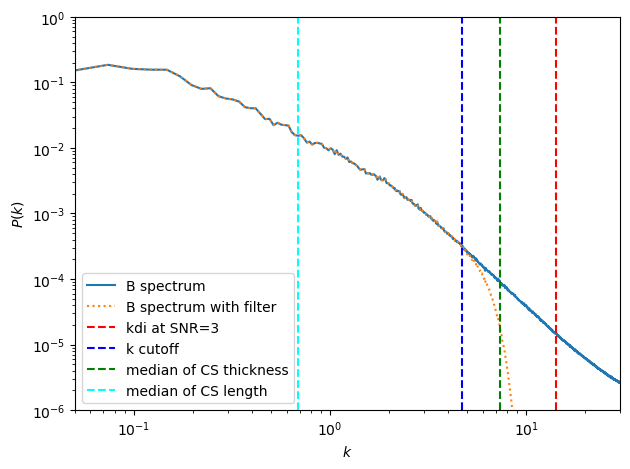

In [4]:
# Plot unfiltered first and capture line objects
plt.rcdefaults()

line_B, = plt.loglog(
    spectrum_B.kk,
    spectrum_B.sp,
    label="B spectrum"
)

plt.loglog(
    spectrum_Bf.kk,
    spectrum_Bf.sp,
    linestyle=":",
    label="B spectrum with filter"
)

plt.xlabel(r"$k$")
plt.ylabel(r"$P(k)$")
plt.xlim(5e-2, 30)
plt.ylim(1e-6, 1)
plt.axvline(x=14.1252, linestyle='--', color='red', label='kdi at SNR=3')
plt.axvline(x=k_cutoff, linestyle='--', color='blue', label='k cutoff')
plt.axvline(x=7.3230597985776065, linestyle='--', color='green', label='median of CS thickness')
plt.axvline(x=0.6859372606091251, linestyle='--', color='cyan', label='median of CS length')

plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "JB_Spectrum", dpi=300)
plt.show()

Extracting 10 snapshots across 10 fork workers (1 thread(s) each), beta_p=1, k=4.706666666666666, Xi=1.6  [VISUALS ON] ...
[1/10] t=245  (M1=198, M2=198, M3=197, cached, 644.1s)
[2/10] t=220  (M1=207, M2=207, M3=207, cached, 686.6s)
[3/10] t=240  (M1=212, M2=212, M3=211, cached, 696.6s)
[4/10] t=235  (M1=217, M2=217, M3=215, cached, 707.7s)
[5/10] t=230  (M1=223, M2=223, M3=221, cached, 731.6s)
[6/10] t=225  (M1=225, M2=225, M3=224, cached, 735.0s)
[7/10] t=205  (M1=232, M2=232, M3=225, cached, 760.6s)
[8/10] t=215  (M1=235, M2=235, M3=232, cached, 776.8s)
[9/10] t=210  (M1=242, M2=242, M3=237, cached, 802.9s)
[10/10] t=200  (M1=249, M2=249, M3=245, cached, 818.6s)

beta_p=1: pooled 10 snapshots (M1=2240, M2=2240, M3=2214) -> cs_thickness_pooled_k/beta_1/pdf_pooled_beta1.png
Done. 3 rows -> cs_thickness_pooled_k/pooled_summary.csv
Pooled figure + .npz under cs_thickness_pooled_k/beta_1/  (+ per-sheet cards in sheets_t<time>/)


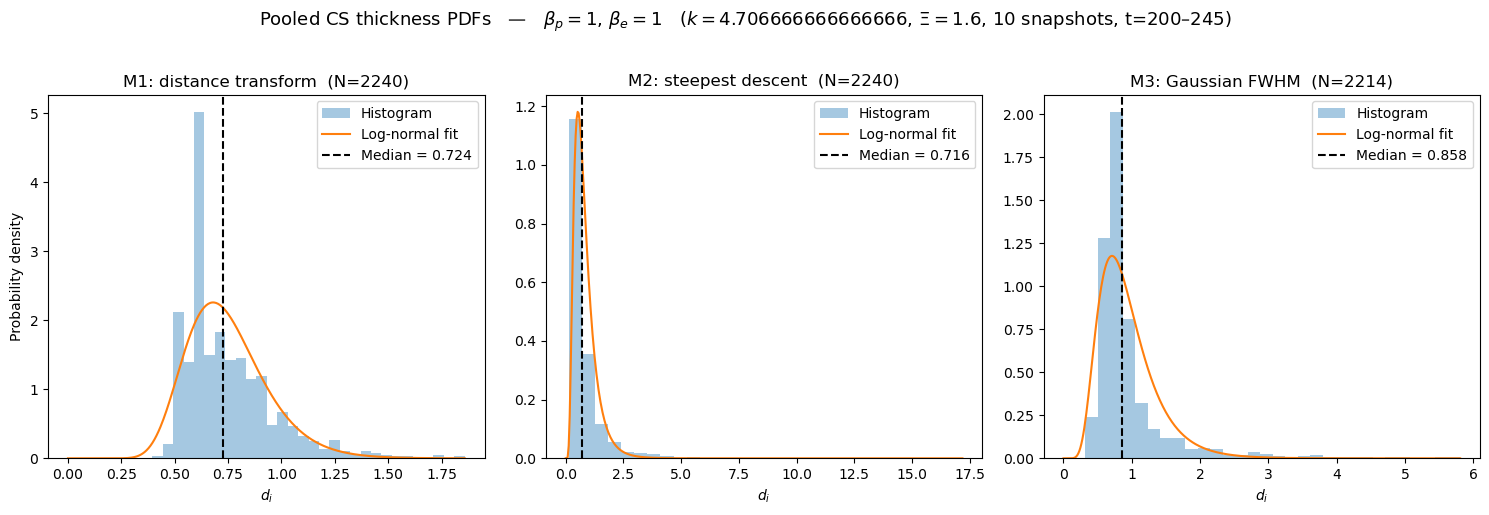

In [5]:
# =====================================================================
# Pool current-sheet thickness over MANY snapshots into one dataset, for a
# SINGLE beta, with an OPTIONAL per-sheet visual-diagnostics mode.
#
# Default (SAVE_SHEET_VISUALS = False): extract per-sheet thicknesses (M1/M2/M3)
# from every snapshot in TIMES, pool them, fit a lognormal, bootstrap the median,
# and save:
#     OUT_ROOT/beta_<BETA>/pdf_pooled_beta<BETA>.png
#     OUT_ROOT/beta_<BETA>/pooled_thicknesses_beta<BETA>.npz
#     OUT_ROOT/pooled_summary.csv
#
# With SAVE_SHEET_VISUALS = True, extraction ALSO writes, per snapshot:
#     OUT_ROOT/beta_<BETA>/sheets_t<time>/overview.png
#     OUT_ROOT/beta_<BETA>/sheets_t<time>/sheet_<k>.png
#
# Uses ONE consistent labeling (CONNECTIVITY) for all three methods, so each
# sheet's M1/M2/M3 are the same region.
#
# ---------------------------------------------------------------------
# WHAT CHANGED FROM THE MULTI-BETA VERSION
#
#  1. ONE beta (BETA = 1), so the per-beta filter table is gone: the filtering is
#     now set by the two numbers K_CUTOFF and XI.
#
#  2. NEW FILTER. iterative_filtering1DWithKCutOff takes ONE field at a time and
#     is parameterised by the cutoff wavenumber k, not by a number of iterations.
#     It is called separately for Bx and By.
#
#  3. THE CACHE NAME HAS CHANGED, deliberately:
#         old:  filtered_beta_{beta}_t{time}_iter{n_iter}_Xi{Xi}.npz
#         new:  filtered_k_beta{BETA}_t{time}_k{K_CUTOFF}_Xi{XI}.npz
#     The new filter removes ONE IMF at a chosen k, where the old one removed
#     n_iter IMFs adaptively -- different fields entirely. Keeping the old name
#     would silently load the old fields. Nothing here can read the old cache,
#     and nothing else you have will read this one.
#
#  4. Bz IS NO LONGER FILTERED. Jz needs only Bx and By, so filtering Bz was a
#     third of the work thrown away. Set FILTER_BZ = True if you want it in the
#     cache for another script (your local-beta scripts use filtered Bz).
#
# Must already exist in your session:
#   iterative_filtering1DWithKCutOff, k_to_mask_length,
#   partial_x_fft, partial_y_fft, detect_current_sheets, dx, dy
# =====================================================================

import os
import csv
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch
import h5py
from skimage import morphology, measure
from skimage.segmentation import find_boundaries
from scipy import ndimage as ndi
from scipy.ndimage import gaussian_filter
from scipy.optimize import curve_fit
from scipy.stats import lognorm
from time import perf_counter
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed

try:
    from threadpoolctl import threadpool_limits
except ImportError:
    threadpool_limits = None

# -----------------------------
# USER SETTINGS
# -----------------------------
BETA  = 1                                 # single run: beta_p = 1, beta_e = 1
TIMES = list(range(200, 250, 5))          # 200, 205, ..., 245 -> pooled

# ---- filtering (the new k-cutoff scheme) ----
K_CUTOFF = k_cutoff          # the k at which the filter cuts; passed straight through
XI       = 1.6         # fifpy Xi
FILTER_BZ = False      # Jz needs only Bx and By. Turn on only if another script
                       # needs filtered Bz out of this cache.

OUT_ROOT  = str(RESULTS / "cs_thickness_pooled_k")
cache_dir = str(CACHE / "filtered_cache_k")
PX_PER_DI = 16.0
N_WORKERS = min(len(TIMES), os.cpu_count() or 1)
N_BOOTSTRAP = 1000
THREADS_PER_WORKER = 1

# ---- debug visuals ----
SAVE_SHEET_VISUALS = True              # <<< per-sheet cards
CONNECTIVITY = 2                        # 2 = 8-connectivity (used for ALL methods)
MAX_SHEETS_VIS = None                   # cap cards per snapshot (None = all); e.g. 25
PAD = 20                                # crop padding around each sheet (px)

# M3 sampling parameters
max_len      = 60
subpix_step  = 0.5
margin_frac  = 0.5
min_half     = 6.0
smooth_sigma = 3

os.makedirs(OUT_ROOT, exist_ok=True)
os.makedirs(cache_dir, exist_ok=True)


# -----------------------------
# Helpers
# -----------------------------
def log(msg):
    print(msg, flush=True)


_WORKER_TL = None


def _init_worker(n_threads):
    global _WORKER_TL
    if threadpool_limits is not None:
        _WORKER_TL = threadpool_limits(limits=n_threads)






# -----------------------------
# Visual diagnostics (only used when SAVE_SHEET_VISUALS)
# -----------------------------
def _render_overview(J2, labeled, nreg, time, visdir):
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(J2.T, origin="lower", cmap="inferno", vmax=float(np.percentile(J2, 99.5)))
    ax.contour(find_boundaries(labeled).T, levels=[0.5], colors="cyan", linewidths=0.4)
    for k in range(1, nreg + 1):
        xr, yr = np.where(labeled == k)
        ax.text(xr.mean(), yr.mean(), str(k), color="white", fontsize=6,
                ha="center", va="center")
    ax.set_title(rf"$\beta_p={BETA}$, $\beta_e=1$, $t={time}$: {nreg} sheets")
    ax.set_xlabel(r"$x/d_p$"); ax.set_ylabel(r"$y/d_p$")
    fig.savefig(os.path.join(visdir, "overview.png"), dpi=200, bbox_inches="tight")
    plt.close(fig)


def _render_card(visdir, time, k, J2, labeled, g):
    """g: dict of per-sheet geometry/measurements."""
    xs_r, ys_r = np.where(labeled == k)
    Nx, Ny = J2.shape
    x0, x1 = max(0, xs_r.min() - PAD), min(Nx, xs_r.max() + PAD + 1)
    y0, y1 = max(0, ys_r.min() - PAD), min(Ny, ys_r.max() + PAD + 1)
    crop = J2[x0:x1, y0:y1]
    regcrop = (labeled[x0:x1, y0:y1] == k)
    ext = [x0, x1, y0, y1]
    xm, ym, dx_, dy_ = g["xm"], g["ym"], g["dx"], g["dy"]

    fig, (axL, axR) = plt.subplots(1, 2, figsize=(11, 5))
    axL.imshow(crop.T, origin="lower", extent=ext, cmap="inferno",
               vmax=float(np.percentile(crop, 99.5)), aspect="equal")
    axL.contour(regcrop.T, levels=[0.5], colors="white", linewidths=1.0, extent=ext)
    axL.plot(xm, ym, "x", color="yellow", ms=11, mew=2, label="max", zorder=6)
    axL.add_patch(Circle((g["epx"], g["epy"]), g["r1"], fill=False, ec="cyan", lw=1.6,
                         label=f"M1 = {g['m1']/PX_PER_DI:.2f}"))
    (xf, yf), (xb, yb) = g["fwd"], g["bwd"]
    axL.plot([xb, xf], [yb, yf], "-", color="lime", lw=2.2,
             label=f"M2 = {g['m2']/PX_PER_DI:.2f}", zorder=5)
    if np.isfinite(g["fwhm"]) and (dx_ or dy_):
        cx, cy = xm + g["mu"] * dx_, ym + g["mu"] * dy_
        ex, ey = (g["fwhm"] / 2) * dx_, (g["fwhm"] / 2) * dy_
        axL.plot([cx - ex, cx + ex], [cy - ey, cy + ey], "-", color="magenta",
                 lw=2.2, label=f"M3 = {g['fwhm']/PX_PER_DI:.2f}", zorder=5)
    if dx_ or dy_:
        axL.add_patch(FancyArrowPatch((xm, ym), (xm + 8 * dx_, ym + 8 * dy_),
                      arrowstyle="->", color="white", mutation_scale=12, lw=1, zorder=6))
    axL.set_xlim(x0, x1); axL.set_ylim(y0, y1)
    axL.set_xlabel(r"$x/d_p$"); axL.set_ylabel(r"$y/d_p$")
    axL.set_title(f"sheet {k}")
    axL.legend(fontsize=7, loc="upper right", framealpha=0.6)

    xs_p, vals_p, popt = g["xs"], g["vals"], g["popt"]
    if xs_p is not None and len(xs_p) > 0:
        axR.plot(xs_p, vals_p, "o", ms=3, color="0.3", label=r"$|J_\parallel|$ profile")
        if popt is not None:
            A, muf, sig, B = popt
            xd = np.linspace(xs_p.min(), xs_p.max(), 400)
            axR.plot(xd, gaussian(xd, A, muf, sig, B), "-", color="magenta",
                     label="Gaussian fit")
            axR.axhline(B + A / 2, color="0.6", ls=":", lw=1, label="half-max")
        axR.set_xlabel("distance along descent (px)")
        axR.set_ylabel(r"$|J_\parallel|$")
        axR.legend(fontsize=8)
    else:
        axR.text(0.5, 0.5, "no profile (flat gradient)", ha="center", va="center",
                 transform=axR.transAxes, color="0.5")

    fig.suptitle(rf"$\beta_p={BETA}$, $\beta_e=1$, $t={time}$, sheet {k}   |   "
                 f"M1={g['m1']/PX_PER_DI:.2f}  M2={g['m2']/PX_PER_DI:.2f}  "
                 f"M3={g['fwhm']/PX_PER_DI:.2f}  $d_i$", fontsize=11)
    fig.tight_layout()
    fig.savefig(os.path.join(visdir, f"sheet_{k:03d}.png"), dpi=130, bbox_inches="tight")
    plt.close(fig)


# -----------------------------
# Per-time thickness extraction (+ optional visuals)
# -----------------------------
def extract_thicknesses(time, verbose=False):
    if SAVE_SHEET_VISUALS and mp.parent_process() is not None:
        plt.switch_backend("Agg")
    _log = log if verbose else (lambda *a, **k: None)
    t0 = perf_counter()
    base_path = f"{DATA_ROOT}/beta_p_{BETA}/beta_e_1/"

    # cache name carries k and Xi, so it cannot collide with the old iter-based cache
    cache_file = f"{cache_dir}/filtered_k_beta{BETA}_t{time}_k{K_CUTOFF}_Xi{XI}.npz"
    cached = os.path.exists(cache_file)

    if cached:
        d = np.load(cache_file)
        data_Bx_f, data_By_f = d["Bx"], d["By"]
    else:
        _log(f"  loading beta={BETA}, t={time} ...")
        with h5py.File(base_path + f"Bx_ApJ_t{time}.h5", "r") as fBx, \
             h5py.File(base_path + f"By_ApJ_t{time}.h5", "r") as fBy:
            data_Bx = fBx["DS1"][:].T
            data_By = fBy["DS1"][:].T

        # the new filter takes ONE field at a time, and a cutoff wavenumber
        _log(f"  filtering beta={BETA}, t={time} (MIF, k={K_CUTOFF}) ...")
        data_Bx_f = iterative_filtering1DWithKCutOff(data_Bx, Xi=XI, k=K_CUTOFF)
        data_By_f = iterative_filtering1DWithKCutOff(data_By, Xi=XI, k=K_CUTOFF)

        to_save = {"Bx": data_Bx_f, "By": data_By_f}
        if FILTER_BZ:                       # only if another script needs it
            with h5py.File(base_path + f"Bz_ApJ_t{time}.h5", "r") as fBz:
                data_Bz = fBz["DS1"][:].T
            to_save["Bz"] = iterative_filtering1DWithKCutOff(data_Bz, Xi=XI, k=K_CUTOFF)
        np.savez_compressed(cache_file, **to_save)

    Jz = partial_x_fft(data_By_f, dy) - partial_y_fft(data_Bx_f, dx)
    J2 = np.abs(Jz)

    sheets = detect_current_sheets(J2)
    mask = np.zeros_like(J2)
    for sheet in sheets:
        for (i, j) in sheet:
            mask[i, j] = 1
    struct = morphology.disk(1)
    mask = morphology.binary_opening(mask, struct)
    mask = morphology.binary_closing(mask, struct)
    cleaned_mask = morphology.remove_small_objects(
        mask.astype(bool), min_size=500).astype(int)

    # ONE consistent labeling for all three methods
    labeled = measure.label(cleaned_mask, connectivity=CONNECTIVITY)
    nreg = int(labeled.max())

    J2_smooth = gaussian_filter(J2, sigma=smooth_sigma)
    gx, gy = np.gradient(J2_smooth)

    visdir = None
    if SAVE_SHEET_VISUALS:
        visdir = os.path.join(OUT_ROOT, f"beta_{BETA}", f"sheets_t{time}")
        os.makedirs(visdir, exist_ok=True)
        _render_overview(J2, labeled, nreg, time, visdir)

    m1_list, m2_list, m3_list = [], [], []
    nvis = 0
    for k in range(1, nreg + 1):
        region = (labeled == k)
        xs_r, ys_r = np.where(region)
        rv = J2[region]
        p = int(np.argmax(rv))
        xm, ym = int(xs_r[p]), int(ys_r[p])

        # M1: inscribed circle from EDT
        edt = ndi.distance_transform_edt(region)
        r1 = float(edt.max()); m1 = 2 * r1
        epx, epy = np.unravel_index(int(np.argmax(edt)), edt.shape)

        # descent direction
        gvec = np.array([gx[xm, ym], gy[xm, ym]])
        if np.allclose(gvec, 0):
            dx_, dy_ = 0.0, 0.0
        else:
            v = -gvec / np.linalg.norm(gvec); dx_, dy_ = float(v[0]), float(v[1])

        # M2: walk to mask edges along descent
        df, fwd = _walk_m2(cleaned_mask, xm, ym, dx_, dy_)
        db, bwd = _walk_m2(cleaned_mask, xm, ym, -dx_, -dy_)
        m2 = df + db

        # M3: Gaussian FWHM along descent
        xs_p, vals_p, popt, fwhm, mu = _m3_profile_and_fit(J2, cleaned_mask, xm, ym, dx_, dy_)

        m1_list.append(m1)
        m2_list.append(m2)
        m3_list.append(fwhm)

        if SAVE_SHEET_VISUALS and (MAX_SHEETS_VIS is None or nvis < MAX_SHEETS_VIS):
            _render_card(visdir, time, k, J2, labeled,
                         {"xm": xm, "ym": ym, "dx": dx_, "dy": dy_,
                          "m1": m1, "epx": epx, "epy": epy, "r1": r1,
                          "m2": m2, "fwd": fwd, "bwd": bwd,
                          "fwhm": fwhm, "mu": mu, "xs": xs_p, "vals": vals_p, "popt": popt})
            nvis += 1

    # returned arrays for pooling (same filters as before)
    m1 = np.array(m1_list, dtype=float)
    m2 = np.array(m2_list, dtype=float); m2 = m2[m2 > 0]
    m3 = np.array(m3_list, dtype=float); m3 = m3[np.isfinite(m3)]; m3 = m3[(m3 > 0) & (m3 <= 100)]

    return {"time": time, "m1": m1, "m2": m2, "m3": m3,
            "n_sheets": nreg, "cached": cached, "elapsed": perf_counter() - t0}


# -----------------------------
# Dispatch extraction (parallel) -> pool -> fit / bootstrap / plot
# -----------------------------
ntime = len(TIMES)
results = []

if N_WORKERS == 1:
    for i, t in enumerate(TIMES, 1):
        try:
            r = extract_thicknesses(t, verbose=True)
            results.append(r)
            log(f"[{i}/{ntime}] t={t} "
                f"(M1={r['m1'].size}, M2={r['m2'].size}, M3={r['m3'].size}, {r['elapsed']:.1f}s)")
        except FileNotFoundError:
            log(f"[{i}/{ntime}] SKIP t={t}: missing file")
        except Exception as e:
            log(f"[{i}/{ntime}] FAIL t={t}: {type(e).__name__}: {e}")
else:
    ctx = mp.get_context("fork")
    if threadpool_limits is None:
        log("note: threadpoolctl not found -> workers may oversubscribe BLAS/FFT threads. "
            "`pip install threadpoolctl` for best utilisation.")
    log(f"Extracting {ntime} snapshots across {N_WORKERS} fork workers "
        f"({THREADS_PER_WORKER} thread(s) each), beta_p={BETA}, k={K_CUTOFF}, Xi={XI}"
        + ("  [VISUALS ON]" if SAVE_SHEET_VISUALS else "") + " ...")
    with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=ctx,
                             initializer=_init_worker, initargs=(THREADS_PER_WORKER,)) as ex:
        futs = {ex.submit(extract_thicknesses, t, False): t for t in TIMES}
        done = 0
        for fut in as_completed(futs):
            t = futs[fut]; done += 1
            try:
                r = fut.result()
                results.append(r)
                src = "cached" if r["cached"] else "filtered"
                log(f"[{done}/{ntime}] t={t}  "
                    f"(M1={r['m1'].size}, M2={r['m2'].size}, M3={r['m3'].size}, "
                    f"{src}, {r['elapsed']:.1f}s)")
            except FileNotFoundError:
                log(f"[{done}/{ntime}] SKIP t={t}: missing file")
            except Exception as e:
                log(f"[{done}/{ntime}] FAIL t={t}: {type(e).__name__}: {e}")

if not results:
    raise SystemExit("no snapshots succeeded -- check paths, TIMES, and the filter")

# ----- pool, fit, bootstrap, plot, save -----
rng = np.random.default_rng(0)
summary_rows = []
panel_spec = [("m1", "M1: distance transform", True),
              ("m2", "M2: steepest descent", False),
              ("m3", "M3: Gaussian FWHM", False)]

times_done = sorted(r["time"] for r in results)
pooled_di = {m: np.concatenate([r[m] for r in results]) / PX_PER_DI
             for m, _, _ in panel_spec}

outdir = os.path.join(OUT_ROOT, f"beta_{BETA}")
os.makedirs(outdir, exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (m, name, yl) in zip(axes, panel_spec):
    st = fit_and_plot_pdf(ax, pooled_di[m], name, ylabel=yl)
    se, lo, hi = bootstrap_lognorm_median(pooled_di[m], N_BOOTSTRAP, rng)
    summary_rows.append({
        "beta": BETA, "k_cutoff": K_CUTOFF, "Xi": XI, "method": name.split(":")[0],
        "n_snapshots": len(times_done), "n_sheets_pooled": st["n"],
        "median_lognorm_di": st["median_lognorm"], "sigma_lognorm": st["sigma_lognorm"],
        "median_se_di": se, "ci_lo_di": lo, "ci_hi_di": hi,
        "mean_di": st["mean"], "median_emp_di": st["median_emp"],
    })
fig.suptitle(rf"Pooled CS thickness PDFs   —   $\beta_p = {BETA}$, $\beta_e = 1$   "
             rf"($k={K_CUTOFF}$, $\Xi={XI}$, {len(times_done)} snapshots, "
             rf"t={times_done[0]}–{times_done[-1]})", y=1.02, fontsize=13)
fig.tight_layout()
figpath = os.path.join(outdir, f"pdf_pooled_beta{BETA}.png")
fig.savefig(figpath, dpi=300, bbox_inches="tight")

np.savez_compressed(os.path.join(outdir, f"pooled_thicknesses_beta{BETA}.npz"),
                    times=np.array(times_done), k_cutoff=K_CUTOFF, Xi=XI,
                    m1_di=pooled_di["m1"], m2_di=pooled_di["m2"], m3_di=pooled_di["m3"])
log(f"\nbeta_p={BETA}: pooled {len(times_done)} snapshots "
    f"(M1={pooled_di['m1'].size}, M2={pooled_di['m2'].size}, "
    f"M3={pooled_di['m3'].size}) -> {figpath}")

# ----- summary CSV -----
csv_path = os.path.join(OUT_ROOT, "pooled_summary.csv")
with open(csv_path, "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=["beta", "k_cutoff", "Xi", "method",
                                      "n_snapshots", "n_sheets_pooled",
                                      "median_lognorm_di", "sigma_lognorm",
                                      "median_se_di", "ci_lo_di", "ci_hi_di",
                                      "mean_di", "median_emp_di"])
    w.writeheader()
    w.writerows(summary_rows)

log(f"Done. {len(summary_rows)} rows -> {csv_path}")
log(f"Pooled figure + .npz under {outdir}/"
    + ("  (+ per-sheet cards in sheets_t<time>/)" if SAVE_SHEET_VISUALS else ""))

measuring 10 snapshots on 10 workers (beta_p=1, k=4.706666666666666, Xi=1.6) ...
IMF 1
IMF 1
IMF 1
IMF 1
IMF 1
IMF 1
IMF 1
IMF 1
(2, 4096, 4096)
(2, 4096, 4096)
(2, 4096, 4096)
IMF 1
IMF 1
IMF 1
(2, 4096, 4096)
IMF 1
(2, 4096, 4096)
IMF 1
(2, 4096, 4096)
(2, 4096, 4096)
IMF 1
IMF 1
(2, 4096, 4096)
IMF 1
(2, 4096, 4096)
(2, 4096, 4096)
(2, 4096, 4096)
(2, 4096, 4096)
(2, 4096, 4096)
  t=40: 54 of 56 sheets fitted
(2, 4096, 4096)
(2, 4096, 4096)
(2, 4096, 4096)
  t=45: 61 of 62 sheets fitted
  t=41: 57 of 58 sheets fitted
  t=42: 55 of 57 sheets fitted
  t=44: 61 of 62 sheets fitted
  t=43: 61 of 63 sheets fitted
  t=46: 64 of 65 sheets fitted
  t=47: 68 of 69 sheets fitted
  t=48: 71 of 74 sheets fitted
  t=49: 79 of 79 sheets fitted

pooled 631 sheets from 10 snapshots
  14 of 645 (2.2%) had no usable M3 fit and are not in the sample
saved -> cs_shape_m3_beta1_k4.706666666666666/shape_beta1.npz (+ .csv)
631 sheets


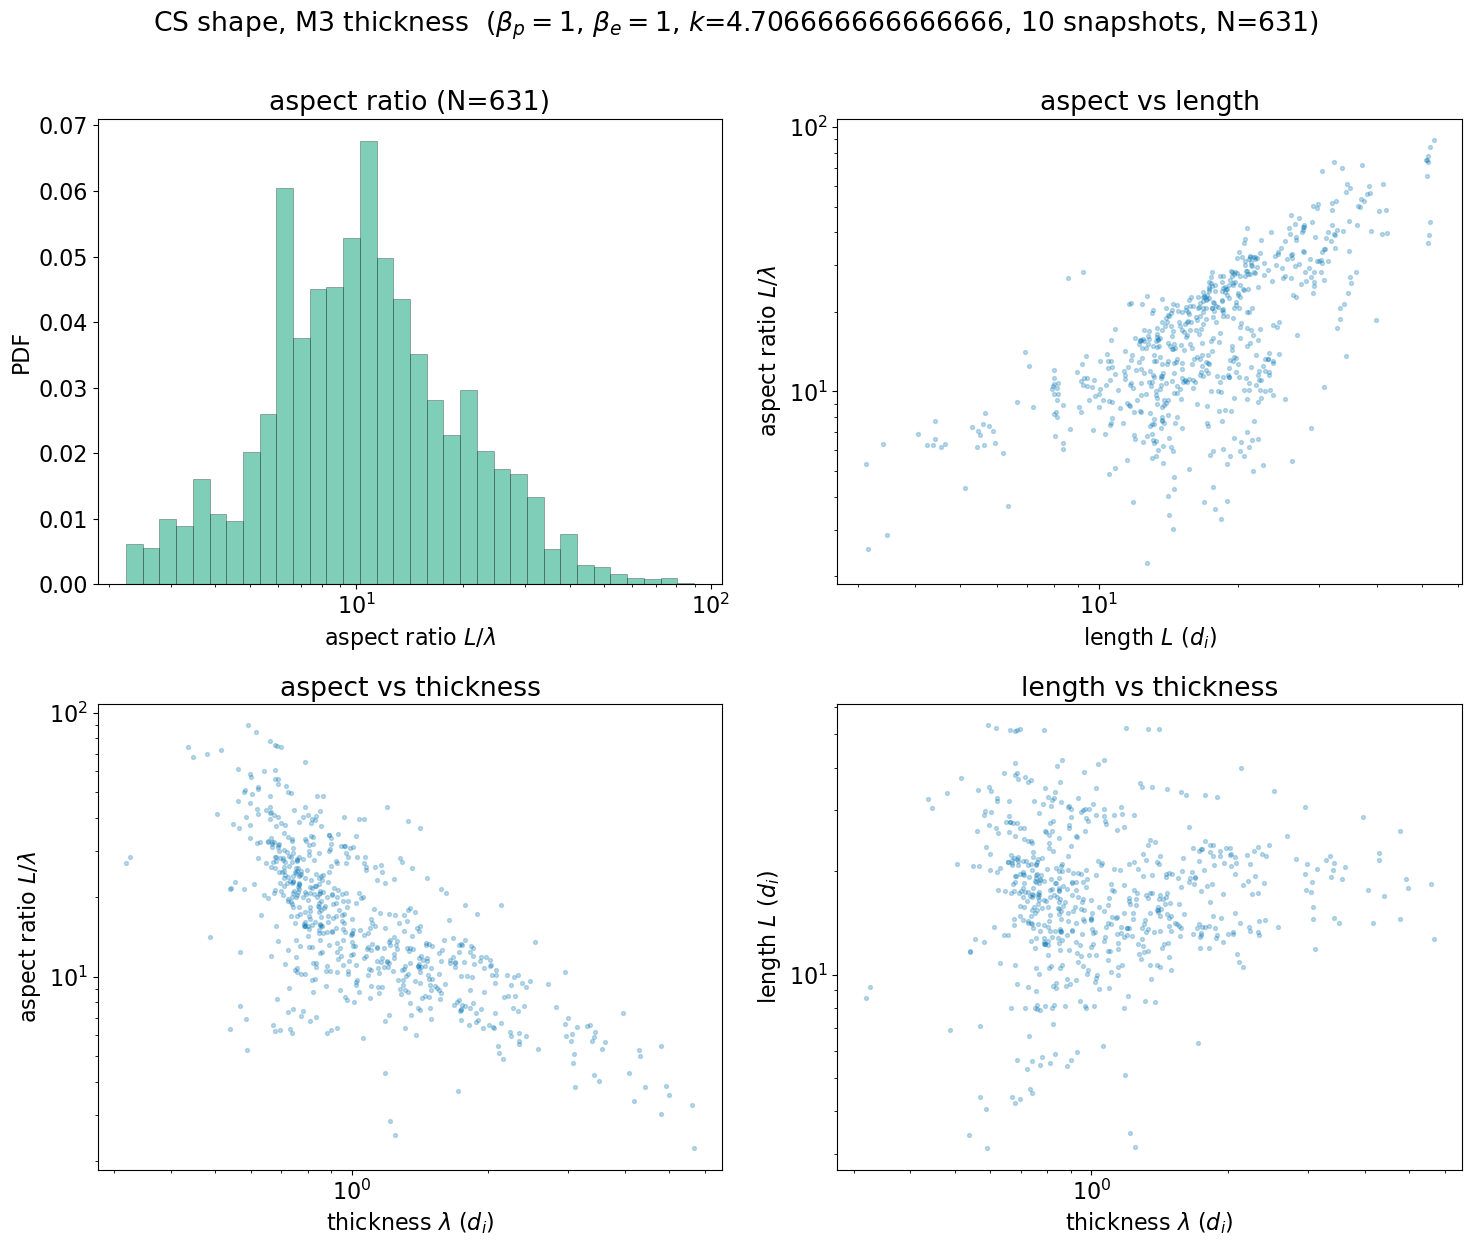

saved cs_shape_m3_beta1_k4.706666666666666/shape_beta1.png

length      : median  17.12 d_i
thickness   : median  0.951 d_i  (M3)
aspect ratio: median   15.2


In [7]:
# %% ==========================================================================
#  CELL 1 -- MEASURE   (run once; the slow part)
# ============================================================================
#  For one beta, with the k-cutoff filtering, measure every current sheet's
#  LENGTH and THICKNESS.
#
#    LENGTH     the longest path along the sheet's middle line (skeletonize).
#
#    THICKNESS  M3: at the sheet's brightest pixel, find the direction the
#               (smoothed) current falls off fastest, read |J_par| along that
#               line, fit a bell curve to it, and take the full width at half
#               maximum:   FWHM = 2 sqrt(2 ln 2) * sigma  ~=  2.3548 * sigma
#
#  M3 rather than the distance-transform thickness, so the width comes from the
#  current PROFILE and does not depend on where the detection threshold happened
#  to put the sheet edge. It also fits a pedestal, so a sheet sitting on a
#  background of |J| is not artificially widened.
#
#  The cost: unlike the distance-transform version, M3 can RETURN NOTHING. A
#  flat, double-peaked or truncated profile makes the fit fail, and those sheets
#  drop out of the sample. The script reports how many.
#
#  Sheets that have closed into a RING around a plasmoid are skipped, as are
#  compact blobs whose middle line is a single pixel.
#
#  Must already exist in your session:
#    iterative_filtering1DWithKCutOff, k_to_mask_length,
#    partial_x_fft, partial_y_fft, detect_current_sheets
# ============================================================================

import os
import csv
import numpy as np
import h5py
from skimage import morphology, measure
from skimage.morphology import skeletonize
from scipy import ndimage as ndi
from scipy.ndimage import gaussian_filter
from scipy.optimize import curve_fit
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed

# -----------------------------
# SETTINGS
# -----------------------------
beta      = 1                           # one run only
TIMES     = list(range(40, 50, 1))    # snapshots to pool together
base_path = f"{DATA_ROOT}/beta_p_{beta}/beta_e_1/"

# ---- the k-cutoff filter ----
K_CUTOFF = k_cutoff          # passed straight to iterative_filtering1DWithKCutOff
XI       = 1.6

cache_dir = str(CACHE / "filtered_cache_k")          # NOT the old iter-based cache: different
out_dir   = str(RESULTS / f"cs_shape_m3_beta{beta}_k{K_CUTOFF}")

STEP          = 1 / 16.0     # one pixel, in units of d_i
MAX_HOLE_AREA = 20           # a hole bigger than this means the sheet rings a plasmoid
N_WORKERS     = min(len(TIMES), os.cpu_count() or 1)

# ---- M3 parameters ----
SMOOTH_SIGMA = 3             # smoothing used ONLY to pick the profile direction
MAX_LEN      = 60            # never sample further than this from the peak (px)
SUBPIX_STEP  = 0.5           # sampling step along the line (px)
MARGIN_FRAC  = 0.5           # sample this much past the sheet edge, so the fit
                             # sees the shoulders and can find the pedestal
MIN_HALF     = 6.0           # always sample at least this far each way (px)
MAX_FWHM_PX  = 100           # reject absurd fits (px)

os.makedirs(cache_dir, exist_ok=True)
os.makedirs(out_dir, exist_ok=True)

NEIGHBOURS = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]


# ============================================================
# STEP A -- length, from the middle line
# ============================================================
def centreline_length(centreline):
    """Longest path along the middle line: walk to the farthest pixel, then from
    there to the farthest again. Returns (length in d_i, number of path pixels)."""
    beads = np.argwhere(centreline)
    if len(beads) < 2:
        return 0.0, 0

    number_at = {(i, j): n for n, (i, j) in enumerate(beads)}
    starts, ends, costs = [], [], []
    for n, (i, j) in enumerate(beads):
        for di, dj in NEIGHBOURS:
            m = number_at.get((i + di, j + dj))
            if m is not None:
                starts.append(n); ends.append(m); costs.append(np.hypot(di, dj) * STEP)
    chain = csr_matrix((costs, (starts, ends)), shape=(len(beads), len(beads)))

    far = dijkstra(chain, indices=0, directed=False)
    one_end = int(np.argmax(np.where(np.isinf(far), -1, far)))
    far = dijkstra(chain, indices=one_end, directed=False)
    far = np.where(np.isinf(far), -1, far)
    return float(far.max()), int(len(beads))


def sheet_length(region):
    """Length of one sheet in d_i, or None if it should be skipped."""
    xs, ys = np.where(region)
    crop = region[xs.min():xs.max() + 1, ys.min():ys.max() + 1]
    crop = np.pad(crop, 2, constant_values=False)

    # skip rings (closed round a plasmoid: a circumference, not an end-to-end span)
    filled = ndi.binary_fill_holes(crop)
    if filled.sum() - crop.sum() > MAX_HOLE_AREA:
        return None
    crop = filled                        # tiny pinholes from thresholding: fill them

    length, npath = centreline_length(skeletonize(crop))
    if npath < 2 or length <= 0:         # a blob that thins to a single pixel
        return None
    return length


# ============================================================
# STEP B -- thickness, M3: fit a bell curve across the sheet
# ============================================================


def sheet_thickness_m3(J_par, mask, region, gx, gy):
    """M3 thickness of one sheet in d_i, or NaN if the fit fails."""
    xs_r, ys_r = np.where(region)
    pk = int(np.argmax(J_par[region]))
    xm, ym = int(xs_r[pk]), int(ys_r[pk])          # brightest pixel in this sheet

    g = np.array([gx[xm, ym], gy[xm, ym]])
    if np.allclose(g, 0):
        return np.nan                              # flat here: no direction to take
    v = -g / np.linalg.norm(g)
    ux, uy = float(v[0]), float(v[1])
    nx, ny = mask.shape

    def edge(sx, sy):
        d = 0.0
        while d < MAX_LEN:
            dn = d + SUBPIX_STEP
            xi, yi = int(round(xm + sx * dn)) % nx, int(round(ym + sy * dn)) % ny
            if not mask[xi, yi]:
                break
            d = dn
        return d

    hf = min(MAX_LEN, max(MIN_HALF, edge(ux, uy) * (1 + MARGIN_FRAC)))
    hb = min(MAX_LEN, max(MIN_HALF, edge(-ux, -uy) * (1 + MARGIN_FRAC)))
    t = np.arange(-hb, hf + SUBPIX_STEP, SUBPIX_STEP)
    prof = ndi.map_coordinates(J_par, np.vstack([xm + t * ux, ym + t * uy]),
                               order=1, mode="grid-wrap")
    if len(prof) < 4:
        return np.nan
    B0, A0 = float(prof.min()), float(prof.max() - prof.min())
    if A0 <= 0:
        return np.nan
    mu0 = float(t[np.argmax(prof)])
    above = np.where(prof >= B0 + 0.5 * A0)[0]
    s0 = (max(1.0, (t[above[-1]] - t[above[0]]) / 2.3548)
          if above.size >= 2 else max(2.0, (hf + hb) / 6.0))
    span = float(t.max() - t.min())
    s0 = min(s0, 0.99 * span)
    try:
        popt, _ = curve_fit(bell, t, prof, p0=[A0, mu0, s0, B0],
                            bounds=([0.0, t.min() - 1, 1e-3, -np.inf],
                                    [np.inf, t.max() + 1, span, np.inf]),
                            maxfev=10000)
    except (RuntimeError, ValueError):
        return np.nan                              # profile too odd for a bell curve
    w = 2 * np.sqrt(2 * np.log(2)) * abs(popt[2])
    return w * STEP if w <= MAX_FWHM_PX else np.nan


# ============================================================
# STEP C -- find the sheets in one snapshot
# ============================================================
def find_sheets(time):
    """Returns (|J_par| field, labelled sheet mask), using the k-cutoff filter."""
    cached = f"{cache_dir}/filtered_k_beta{beta}_t{time}_k{K_CUTOFF}_Xi{XI}.npz"
    if os.path.exists(cached):
        d = np.load(cached)
        Bxf, Byf = d["Bx"], d["By"]
    else:
        with h5py.File(base_path + f"Bx_ApJ_t{time}.h5", "r") as fx, \
             h5py.File(base_path + f"By_ApJ_t{time}.h5", "r") as fy:
            Bx, By = fx["DS1"][:].T, fy["DS1"][:].T
        # one field at a time, cut at k = K_CUTOFF.  Bz is not loaded: J_par
        # needs only Bx and By
        Bxf = iterative_filtering1DWithKCutOff(Bx, Xi=XI, k=K_CUTOFF)
        Byf = iterative_filtering1DWithKCutOff(By, Xi=XI, k=K_CUTOFF)
        np.savez_compressed(cached, Bx=Bxf, By=Byf)

    J_par = np.abs(partial_x_fft(Byf, STEP) - partial_y_fft(Bxf, STEP))

    mask = np.zeros_like(J_par)
    for sheet in detect_current_sheets(J_par):
        for (i, j) in sheet:
            mask[i, j] = 1
    disk = morphology.disk(1)
    mask = morphology.binary_opening(mask, disk)
    mask = morphology.binary_closing(mask, disk)
    cleaned = morphology.remove_small_objects(mask.astype(bool), min_size=500)
    return J_par, cleaned, measure.label(cleaned, connectivity=2)


def measure_snapshot(time):
    J_par, cleaned, labelled = find_sheets(time)
    # the direction for M3 comes from the SMOOTHED current, so it is not thrown
    # off by pixel-to-pixel noise
    gx, gy = np.gradient(gaussian_filter(J_par, sigma=SMOOTH_SIGMA))

    rows, n_tried = [], 0
    for k in range(1, int(labelled.max()) + 1):
        region = (labelled == k)
        L = sheet_length(region)
        if L is None:
            continue                     # a ring, or no measurable middle line
        n_tried += 1
        th = sheet_thickness_m3(J_par, cleaned, region, gx, gy)
        if not np.isfinite(th) or th <= 0:
            continue                     # M3 could not fit this profile
        rows.append([time, k, L, th])
    return time, rows, n_tried


COLUMNS = ["time", "sheet", "length", "thickness_m3"]


# ============================================================
# STEP D -- run every snapshot, pool, save
# ============================================================
all_rows, total_tried = [], 0
print(f"measuring {len(TIMES)} snapshots on {N_WORKERS} workers "
      f"(beta_p={beta}, k={K_CUTOFF}, Xi={XI}) ...", flush=True)
with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=mp.get_context("fork")) as pool:
    jobs = {pool.submit(measure_snapshot, t): t for t in TIMES}
    for job in as_completed(jobs):
        try:
            time, rows, tried = job.result()
            all_rows += rows; total_tried += tried
            print(f"  t={time}: {len(rows)} of {tried} sheets fitted", flush=True)
        except FileNotFoundError:
            print(f"  t={jobs[job]}: file missing, skipped", flush=True)

if not all_rows:
    raise SystemExit("no sheets measured -- check the paths, TIMES and the filter")

data  = np.array(sorted(all_rows, key=lambda r: (r[0], r[1])), float)
times = sorted(set(data[:, 0].astype(int).tolist()))
lost = total_tried - len(data)
print(f"\npooled {len(data)} sheets from {len(times)} snapshots")
print(f"  {lost} of {total_tried} ({100*lost/max(total_tried,1):.1f}%) had no usable "
      f"M3 fit and are not in the sample")

np.savez_compressed(f"{out_dir}/shape_beta{beta}.npz", data=data,
                    cols=np.array(COLUMNS), times=np.array(times),
                    beta=beta, step=STEP, k_cutoff=K_CUTOFF, Xi=XI)
with open(f"{out_dir}/shape_beta{beta}.csv", "w", newline="") as f:
    w = csv.writer(f); w.writerow(COLUMNS); w.writerows(data.tolist())
print(f"saved -> {out_dir}/shape_beta{beta}.npz (+ .csv)")


# %% ==========================================================================
#  CELL 2 -- PLOT   (re-run as often as you like; nothing is recomputed)
# ============================================================================

import os
import glob
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 16})
BLUE, GREEN = "#0072B2", "#009E73"

try:
    data
except NameError:
    found = glob.glob(str(RESULTS / "cs_shape_m3_beta*" / "shape_beta*.npz"))
    if not found:
        raise SystemExit("no saved results found -- run CELL 1 first")
    newest = max(found, key=os.path.getmtime)
    d = np.load(newest, allow_pickle=True)
    data, COLUMNS, times = d["data"], list(d["cols"]), d["times"].tolist()
    beta, STEP = d["beta"].item(), d["step"].item()
    K_CUTOFF, XI = d["k_cutoff"].item(), d["Xi"].item()
    out_dir = os.path.dirname(newest)
    print(f"loaded {newest}  (beta_p = {beta}, k = {K_CUTOFF})")

col       = {n: i for i, n in enumerate(COLUMNS)}
length    = data[:, col["length"]]
thickness = data[:, col["thickness_m3"]]
ok = np.isfinite(length) & np.isfinite(thickness) & (length > 0) & (thickness > 0)
length, thickness = length[ok], thickness[ok]
aspect = length / thickness
print(f"{len(length)} sheets")

fig, ax = plt.subplots(2, 2, figsize=(15, 12.5))

# 1. aspect ratio histogram
ax[0, 0].hist(aspect, bins=np.logspace(np.log10(aspect.min()),
                                       np.log10(aspect.max()), 35),
              density=True, alpha=0.5, color=GREEN, edgecolor="black", linewidth=0.4)
ax[0, 0].set_xscale("log")
ax[0, 0].set_xlabel(r"aspect ratio $L/\lambda$"); ax[0, 0].set_ylabel("PDF")
ax[0, 0].set_title(f"aspect ratio (N={len(aspect)})")

# 2. aspect vs length
ax[0, 1].scatter(length, aspect, s=8, alpha=0.25, color=BLUE)
ax[0, 1].set_xscale("log"); ax[0, 1].set_yscale("log")
ax[0, 1].set_xlabel(r"length $L$ $(d_i)$"); ax[0, 1].set_ylabel(r"aspect ratio $L/\lambda$")
ax[0, 1].set_title("aspect vs length")

# 3. aspect vs thickness
ax[1, 0].scatter(thickness, aspect, s=8, alpha=0.25, color=BLUE)
ax[1, 0].set_xscale("log"); ax[1, 0].set_yscale("log")
ax[1, 0].set_xlabel(r"thickness $\lambda$ $(d_i)$")
ax[1, 0].set_ylabel(r"aspect ratio $L/\lambda$")
ax[1, 0].set_title("aspect vs thickness")

# 4. length vs thickness
ax[1, 1].scatter(thickness, length, s=8, alpha=0.25, color=BLUE)
ax[1, 1].set_xscale("log"); ax[1, 1].set_yscale("log")
ax[1, 1].set_xlabel(r"thickness $\lambda$ $(d_i)$"); ax[1, 1].set_ylabel(r"length $L$ $(d_i)$")
ax[1, 1].set_title("length vs thickness")

fig.suptitle(rf"CS shape, M3 thickness  ($\beta_p={beta}$, $\beta_e=1$, "
             rf"$k$={K_CUTOFF}, {len(times)} snapshots, N={len(length)})", y=1.00)
fig.tight_layout()
fig.savefig(f"{out_dir}/shape_beta{beta}.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"saved {out_dir}/shape_beta{beta}.png")

print(f"\nlength      : median {np.median(length):6.2f} d_i")
print(f"thickness   : median {np.median(thickness):6.3f} d_i  (M3)")
print(f"aspect ratio: median {np.median(aspect):6.1f}")